### This script is a simple, end-to-end example of a machine learning project.
###### It uses the Melbourne Housing Snapshot dataset from Kaggle to predict house prices.

### Importing necessary libraries

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

print("Libraries imported successfully.")

Libraries imported successfully.


### Load and prepare data
###### The dataset is expected to be in a 'data' folder at the same level as this script.
###### Dataset URL: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

In [5]:
# try:
data = pd.read_csv("/home/abhinay/python/house/data/melb_data.csv")
# except FileNotFoundError:
#     print("Error: 'melb_data.csv' not found. Please download the dataset and place it in the data folder.")
#     exit()

### Drop rows with missing target values

In [6]:
data.dropna(axis=0, subset=['Price'], inplace=True)

### Selecting a few features to make the model simple

In [7]:
features = ['Rooms', 'Bathroom', 'Landsize', 'Lattitude', 'Longtitude']
y = data.Price
X = data[features]

In [17]:
print("\nData preparation complete.")
print(f"Number of rows after removing missing prices: {X.shape[0]}")
print(f"Selected features: {features}")
print("\nFirst 5 rows of the features:")
print(X.head())
print("\nPrice for the following for comparision")
y.head()


Data preparation complete.
Number of rows after removing missing prices: 13580
Selected features: ['Rooms', 'Bathroom', 'Landsize', 'Lattitude', 'Longtitude']

First 5 rows of the features:
   Rooms  Bathroom  Landsize  Lattitude  Longtitude
0      2       1.0     202.0   -37.7996    144.9984
1      2       1.0     156.0   -37.8079    144.9934
2      3       2.0     134.0   -37.8093    144.9944
3      3       2.0      94.0   -37.7969    144.9969
4      4       1.0     120.0   -37.8072    144.9941

Price for the following for comparision


0    1480000.0
1    1035000.0
2    1465000.0
3     850000.0
4    1600000.0
Name: Price, dtype: float64


Generating simple EDA plots...


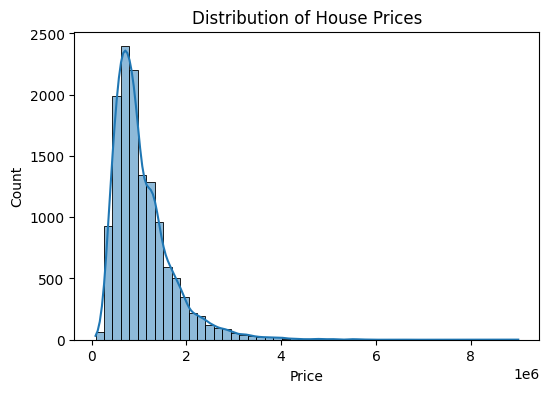

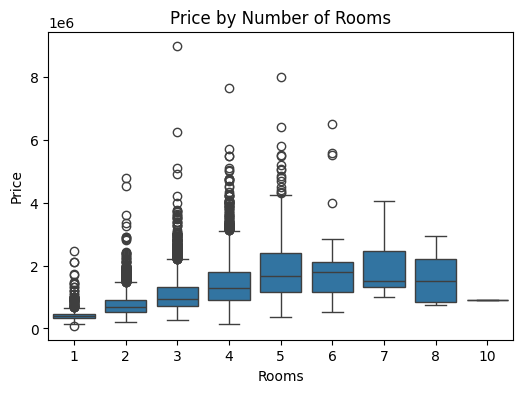

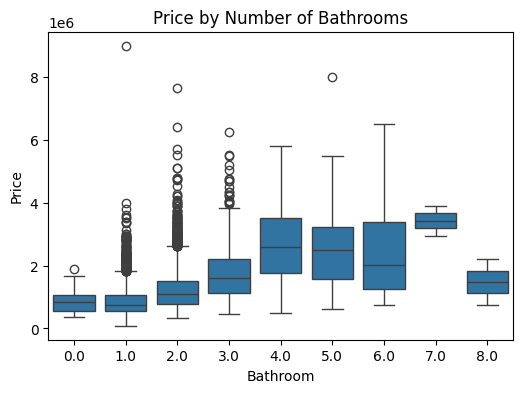

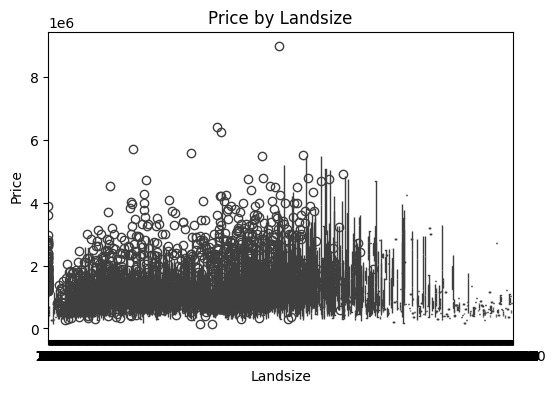

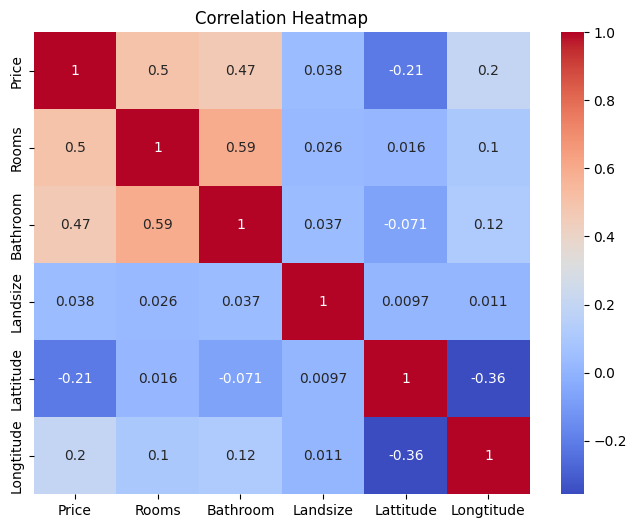

In [18]:
print("\nGenerating simple EDA plots...")

# 1. Price distribution
plt.figure(figsize=(6,4))
sns.histplot(data['Price'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# 2. Rooms vs Price
plt.figure(figsize=(6,4))
sns.boxplot(x="Rooms", y="Price", data=data)
plt.title("Price by Number of Rooms")
plt.show()

# 3. Bathroom vs Price
plt.figure(figsize=(6,4))
sns.boxplot(x="Bathroom", y="Price", data=data)
plt.title("Price by Number of Bathrooms")
plt.show()

# 4. Rooms vs Price
plt.figure(figsize=(6,4))
sns.boxplot(x="Landsize", y="Price", data=data)
plt.title("Price by Landsize")
plt.show()

# 5. Correlation heatmap (numerical features only)
plt.figure(figsize=(8,6))
corr = data[['Price','Rooms','Bathroom','Landsize','Lattitude','Longtitude']].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

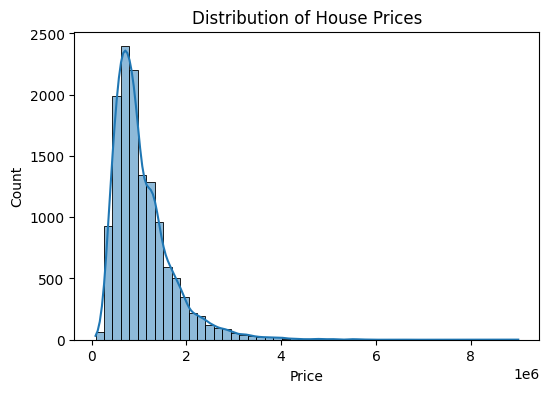

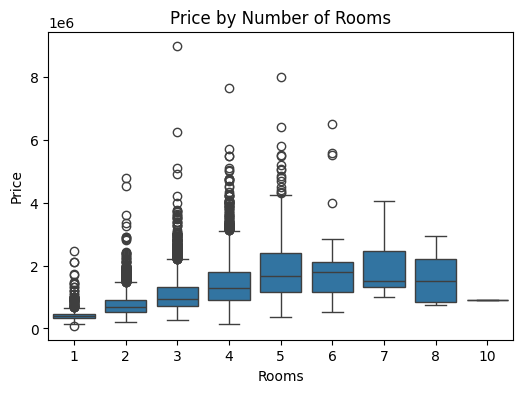

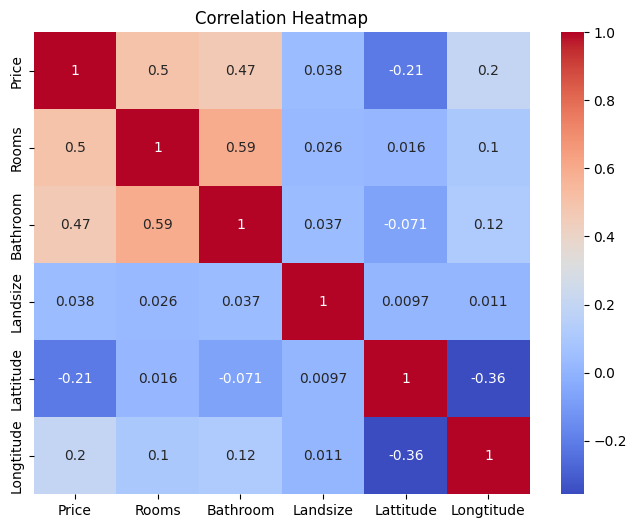

In [15]:
# Example 1: Price histogram
plt.figure(figsize=(6,4))
sns.histplot(data['Price'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Count")
# plt.savefig("plots/price_hist.png")  # <-- save plot to folder
plt.show()

# Example 2: Price vs Rooms
plt.figure(figsize=(6,4))
sns.boxplot(x="Rooms", y="Price", data=data)
plt.title("Price by Number of Rooms")
# plt.savefig("plots/boxplot_price_rooms.png")
plt.show()

# Example 3: Correlation heatmap
plt.figure(figsize=(8,6))
corr = data[['Price','Rooms','Bathroom','Landsize','Lattitude','Longtitude']].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
# plt.savefig("plots/corr_heatmap.png")
plt.show()

### Split the data into training and validation sets
###### This step is crucial for evaluating how well the model performs on unseen data.

In [11]:
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)
print("\nData split into training and validation sets")
print(f"Training set size: {len(train_X)} rows")
print(f"Validation set size: {len(val_X)} rows")


Data split into training and validation sets
Training set size: 10185 rows
Validation set size: 3395 rows


### Define and train the model

In [ ]:
# First we will use a Decision Tree Regressor model with limited depth to avoid overfitting.
dt_model = DecisionTreeRegressor(max_depth=10, random_state=1)
dt_model.fit(train_X, train_y)

print("\nDecision Tree model training complete.")

# Next, we will try a Random Forest Regressor for comparison.
rf_model = RandomForestRegressor(random_state=1)
rf_model.fit(train_X, train_y)

print("Random Forest model training complete.")


Decision Tree model training complete.
Random Forest model training complete.


### Make Predictions and Evaluate the Models

In [13]:
print("\nMaking predictions on the validation set...")

# Decision Tree predictions
dt_val_predictions = dt_model.predict(val_X)
dt_mae = mean_absolute_error(val_y, dt_val_predictions)

# Random Forest predictions
rf_val_predictions = rf_model.predict(val_X)
rf_mae = mean_absolute_error(val_y, rf_val_predictions)

print(f"Decision Tree Mean Absolute Error (MAE): ${dt_mae:,.2f}")
print(f"Random Forest Mean Absolute Error (MAE): ${rf_mae:,.2f}")


Making predictions on the validation set...
Decision Tree Mean Absolute Error (MAE): $223,644.81
Random Forest Mean Absolute Error (MAE): $180,544.07


### Example Prediction for a New House
###### You can use the trained model to predict the price of a new, unseen house.

In [14]:
new_house_data = pd.DataFrame([[2, 1, 150, -37.8, 145.0]], columns=features)

dt_predicted_price = dt_model.predict(new_house_data)[0]
rf_predicted_price = rf_model.predict(new_house_data)[0]

print("\n--- Example Prediction ---")
print(f"Predicting the price for a new house with features: {new_house_data.iloc[0].to_dict()}")
print(f"Decision Tree Predicted Price: ${dt_predicted_price:,.2f}")
print(f"Random Forest Predicted Price: ${rf_predicted_price:,.2f}")


--- Example Prediction ---
Predicting the price for a new house with features: {'Rooms': 2.0, 'Bathroom': 1.0, 'Landsize': 150.0, 'Lattitude': -37.8, 'Longtitude': 145.0}
Decision Tree Predicted Price: $1,112,718.71
Random Forest Predicted Price: $1,052,885.00
